# 02. 収集データのレビュー

`01_collect_data.ipynb` で集めたデータ(各エピソードの `video.mp4` + `actions.csv`)を可視化して確認します。
学習 (`03_train_bc.ipynb`) に進む前に、意図した通りのデータが集まっているかをここで確認してください。
このノートブックは読み取り専用で、データ収集や学習には影響しません。

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA_DIR = Path("../data")
MANIFEST_PATH = DATA_DIR / "manifest.csv"
EPISODES_DIR = DATA_DIR / "episodes"

manifest = pd.read_csv(MANIFEST_PATH)
manifest

,episode_id,num_frames,score,x_pos_max,coins,flag_get,time_remaining,truncated,timestamp
0,ep_20260802_144331,290,200,296,1,False,371,False,2026-08-02 14:43:31
1,ep_20260802_144503,2716,6000,3161,13,True,138,False,2026-08-02 14:45:03
2,ep_20260802_144506,89,200,297,1,False,392,False,2026-08-02 14:45:06
3,ep_20260802_144515,253,100,800,0,False,375,False,2026-08-02 14:45:15
4,ep_20260802_144518,80,200,296,1,False,392,False,2026-08-02 14:45:18
5,ep_20260802_144616,1731,2200,3161,3,True,233,False,2026-08-02 14:46:16
6,ep_20260802_144638,634,600,2008,0,False,337,False,2026-08-02 14:46:38
7,ep_20260802_144639,37,0,79,0,False,397,True,2026-08-02 14:46:39
8,ep_20260802_145236,1521,300,3161,0,True,248,False,2026-08-02 14:52:36
9,ep_20260802_145238,68,0,164,0,False,394,True,2026-08-02 14:52:38


## 要約統計

In [2]:
print(f"episodes: {len(manifest)}")
print(f"clear rate (flag_get): {manifest['flag_get'].mean():.1%}")
manifest[["num_frames", "score", "x_pos_max", "coins", "time_remaining"]].describe()

episodes: 50
clear rate (flag_get): 24.0%


,num_frames,score,x_pos_max,coins,time_remaining
count,50.000000,50.000000,50.000000,50.000000,50.000000
mean,729.220000,617.000000,1621.620000,1.220000,325.100000
std,790.769537,1161.614376,1142.005556,2.581646,77.573204
min,18.000000,0.000000,60.000000,0.000000,94.000000
25%,168.250000,0.000000,673.750000,0.000000,292.500000
50%,470.500000,200.000000,1519.000000,0.000000,351.000000
75%,967.000000,600.000000,2749.000000,1.000000,383.250000
max,3123.000000,6000.000000,3161.000000,13.000000,397.000000


## プレイのうまさ評価 (Skillスコア)

エピソード1本の出来を0〜100点で総合評価する。

```
progress = min(x_pos_max / 3161, 1)                          # 到達率 (3161 = ゴールのx座標)
clear    = 1 if flag_get else 0                              # クリアしたか
t_used   = 400 - time_remaining                              # 消費したゲーム内時間
speed    = clear × clip((T_SLOW - t_used) / (T_SLOW - T_FAST), 0, 1)
collect  = min(coins / COIN_TARGET, 1)                       # コイン収集

Skill = 100 × (0.45·progress + 0.30·clear + 0.15·speed + 0.10·collect)
```

- **進んだ距離を主軸(45%)** にし、ゴール到達には別枠のボーナス(30%)を与える。
  「あと少しで死んだ」と「クリアした」は質的に違うため。
- **速さはクリアしたエピソードにのみ加点**する。死んだエピソードの「速さ」は
  早く死んだだけで上手さではないため `clear` を掛けて無効化している。
  時間は `num_frames` ではなくゲーム内タイマーを使う (土管などのエリア遷移中は
  環境が内部でフレームを進めるため、記録フレーム数は実際の経過時間とずれる)。
- **`score` は使わない。** エピソードはポールに触れた瞬間に終了する判定なので、
  ポール降下点・残タイムボーナスが加算される前の値しか記録されず、
  クリアしたエピソードほど不当に低く出てしまう。収集の上手さはコイン枚数で見る。
- `truncated=True` (Escで中断) の行は、途中でやめただけで実力とは無関係なので除外する。

`T_FAST` / `T_SLOW` は手元のクリア済みエピソードの消費時間に合わせて調整する。

In [3]:
# --- Skill score: keep these constants and the formula identical to 01_collect_data.ipynb ---
X_GOAL = 3161  # x position of the flagpole in world 1-1
T_FAST = 110  # full speed score at or below this time
T_SLOW = 260  # zero speed score at or above this time
COIN_TARGET = 10  # full collection score at this many coins

WEIGHTS = {"progress": 0.45, "clear": 0.30, "speed": 0.15, "collect": 0.10}


def add_skill_score(df: pd.DataFrame) -> pd.DataFrame:
    """Return the manifest with a Skill score and its component terms added."""
    out = df.copy()
    out["progress"] = (out["x_pos_max"] / X_GOAL).clip(upper=1.0)
    out["clear"] = out["flag_get"].astype(int)
    out["t_used"] = 400 - out["time_remaining"]
    out["speed"] = out["clear"] * ((T_SLOW - out["t_used"]) / (T_SLOW - T_FAST)).clip(0, 1)
    out["collect"] = (out["coins"] / COIN_TARGET).clip(upper=1.0)
    out["skill"] = 100 * sum(WEIGHTS[k] * out[k] for k in WEIGHTS)
    return out
# --- end of shared block ---


# Rows cut short with ESC only mean the player stopped, so leave them out
scored = add_skill_score(manifest[~manifest["truncated"]])

print(f"scored: {len(scored)} episodes (excluded: {int(manifest['truncated'].sum())})")
print(f"mean skill: {scored['skill'].mean():.1f}   best: {scored['skill'].max():.1f}")
print(f"clear rate: {scored['clear'].mean():.0%}")

scored.sort_values("skill", ascending=False)[
    ["episode_id", "x_pos_max", "flag_get", "t_used", "coins",
     "progress", "speed", "collect", "skill"]
].round(2)

scored: 46 episodes (excluded: 4)
mean skill: 36.1   best: 90.0
clear rate: 26%


,episode_id,x_pos_max,flag_get,t_used,coins,progress,speed,collect,skill
42,ep_20260905_142217,3161,True,109,0,1.00,1.00,0.0,90.00
14,ep_20260905_121910,3161,True,122,1,1.00,0.92,0.1,89.80
49,ep_20260905_142831,3161,True,118,0,1.00,0.95,0.0,89.20
40,ep_20260905_141733,3161,True,147,2,1.00,0.75,0.2,88.30
16,ep_20260905_123457,3161,True,133,0,1.00,0.85,0.0,87.70
5,ep_20260802_144616,3161,True,167,3,1.00,0.62,0.3,87.30
48,ep_20260905_142432,3161,True,150,1,1.00,0.73,0.1,87.00
8,ep_20260802_145236,3161,True,152,0,1.00,0.72,0.0,85.80
1,ep_20260802_144503,3161,True,262,13,1.00,0.00,1.0,85.00
31,ep_20260905_140950,3161,True,305,12,1.00,0.00,1.0,85.00


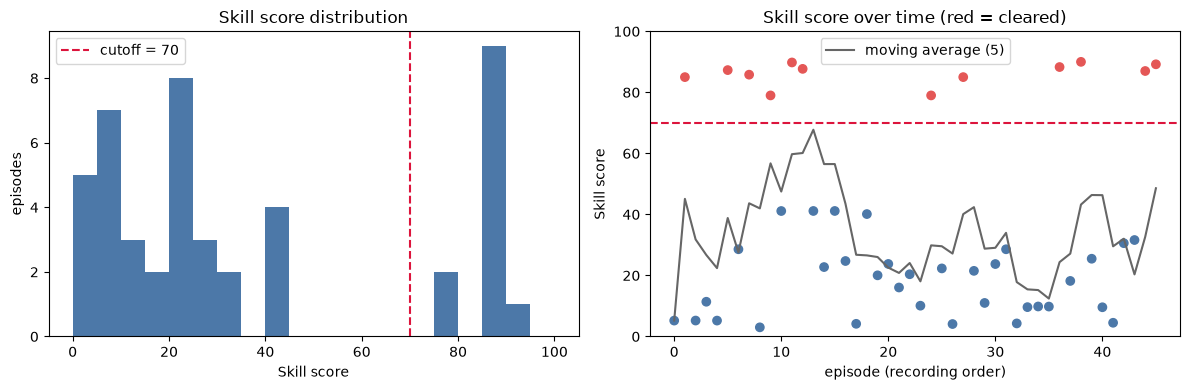

skill >= 70: 12 / 46 episodes
['ep_20260905_142217', 'ep_20260905_121910', 'ep_20260905_142831', 'ep_20260905_141733', 'ep_20260905_123457', 'ep_20260802_144616', 'ep_20260905_142432', 'ep_20260802_145236', 'ep_20260905_140950', 'ep_20260802_144503', 'ep_20260905_120712', 'ep_20260905_134743']


In [4]:
# Skill score distribution, and whether play improves as episodes accumulate
GOOD_SKILL = 70  # cutoff for keeping an episode as training data (in practice, the cleared ones)

fig, (ax_hist, ax_time) = plt.subplots(1, 2, figsize=(12, 4))

ax_hist.hist(scored["skill"], bins=20, range=(0, 100), color="#4c78a8")
ax_hist.axvline(GOOD_SKILL, color="crimson", linestyle="--", label=f"cutoff = {GOOD_SKILL}")
ax_hist.set_xlabel("Skill score")
ax_hist.set_ylabel("episodes")
ax_hist.set_title("Skill score distribution")
ax_hist.legend()

chronological = scored.sort_values("timestamp").reset_index(drop=True)
colors = ["#e45756" if c else "#4c78a8" for c in chronological["clear"]]
ax_time.scatter(chronological.index, chronological["skill"], c=colors)
ax_time.plot(
    chronological.index,
    chronological["skill"].rolling(5, min_periods=1).mean(),
    color="#666",
    label="moving average (5)",
)
ax_time.axhline(GOOD_SKILL, color="crimson", linestyle="--")
ax_time.set_xlabel("episode (recording order)")
ax_time.set_ylabel("Skill score")
ax_time.set_ylim(0, 100)
ax_time.set_title("Skill score over time (red = cleared)")
ax_time.legend()

plt.tight_layout()
plt.show()

good = scored[scored["skill"] >= GOOD_SKILL].sort_values("skill", ascending=False)
print(f"skill >= {GOOD_SKILL}: {len(good)} / {len(scored)} episodes")
print(good["episode_id"].tolist())

## アクション分布 (全エピソード合計)

学習時のクラス不均衡を事前に把握するために、7種類のアクションそれぞれが何フレーム記録されたかを集計する。

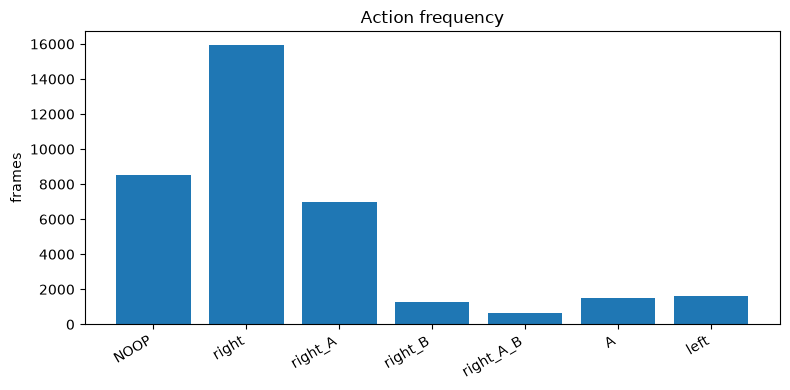

In [5]:
from collections import Counter

from gym_super_mario_bros.actions import SIMPLE_MOVEMENT

ACTION_NAMES = ["_".join(a) if a else "NOOP" for a in SIMPLE_MOVEMENT]

action_counts = Counter()
for ep_dir in sorted(EPISODES_DIR.glob("ep_*")):
    actions_csv = ep_dir / "actions.csv"
    if not actions_csv.exists():
        continue
    action_counts.update(pd.read_csv(actions_csv)["action"].tolist())

counts = [action_counts.get(i, 0) for i in range(len(SIMPLE_MOVEMENT))]

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(ACTION_NAMES, counts)
ax.set_ylabel("frames")
ax.set_title("Action frequency")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## エピソードのフレームサンプル表示

`episode_id` を変えて、別のエピソードを確認できる。

ep_20260802_144331: video=290 frames, actions.csv=290 frames


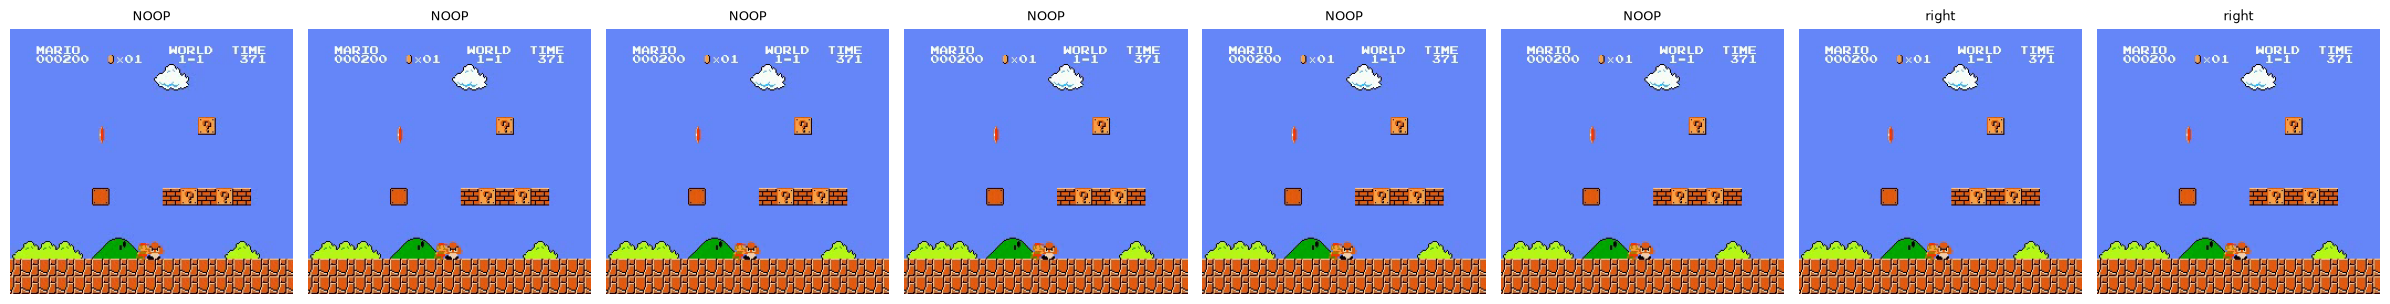

In [6]:
import cv2
import numpy as np

episode_id = manifest["episode_id"].iloc[0]  # change this to the episode you want to inspect
ep_dir = EPISODES_DIR / episode_id
actions_df = pd.read_csv(ep_dir / "actions.csv")

cap = cv2.VideoCapture(str(ep_dir / "video.mp4"))
num_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
print(f"{episode_id}: video={num_frames} frames, actions.csv={len(actions_df)} frames")

n_samples = min(8, num_frames)
sample_idx = np.linspace(0, num_frames - 1, num=n_samples, dtype=int)

sample_frames = []
for idx in sample_idx:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
    ok, frame_bgr = cap.read()
    sample_frames.append(cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB) if ok else None)
cap.release()

fig, axes = plt.subplots(1, n_samples, figsize=(3 * n_samples, 3))
if n_samples == 1:
    axes = [axes]
for ax, idx, frame in zip(axes, sample_idx, sample_frames):
    action_idx = int(actions_df.loc[actions_df["frame_idx"] == idx, "action"].iloc[0])
    if frame is not None:
        ax.imshow(frame)
    ax.set_title(ACTION_NAMES[action_idx], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## アクション系列の時系列プロット

選択したエピソード内で、どのタイミングでどのアクションを取ったかを確認できる(ジャンプのタイミング等)。

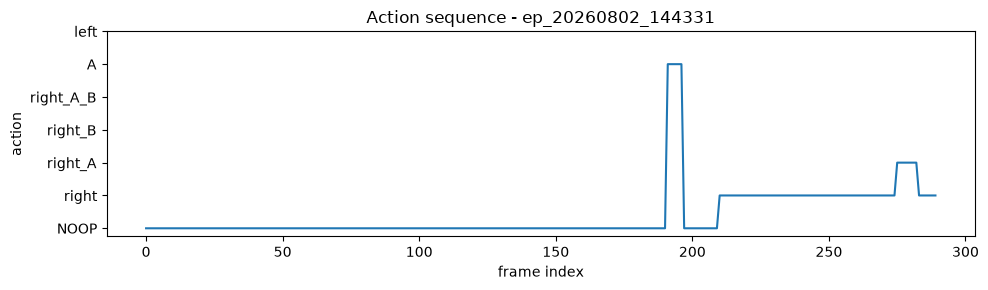

In [7]:
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(actions_df["frame_idx"], actions_df["action"])
ax.set_xlabel("frame index")
ax.set_ylabel("action")
ax.set_yticks(range(len(SIMPLE_MOVEMENT)))
ax.set_yticklabels(ACTION_NAMES)
ax.set_title(f"Action sequence - {episode_id}")
plt.tight_layout()
plt.show()

## データのクリーニング

数フレームしかない、記録ミスなど明らかにおかしいエピソードが見つかった場合は、
該当する `data/episodes/ep_YYYYMMDD_HHMMSS/` フォルダ(`video.mp4` と `actions.csv`)を削除し、
`data/manifest.csv` から対応する行を手動で削除してください。
上のSkillスコアが極端に低いエピソード(進んでいない・すぐ死んだ)が候補になります。

エピソードIDは記録時刻から作られるため一意です。連番だった頃のデータは
`ep_0000` のようなIDが再利用されていて、manifestの行とフォルダの対応が
取れなくなっていました(移行済み。旧manifestは `data/manifest_backup_*.csv` に保存)。